In [1]:
from types import SimpleNamespace

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import matplotlib
from matplotlib import pyplot as plt
from mpl_toolkits import mplot3d
import numpy as np

import kwant

import scipy.linalg as la
from math import atan2, pi, sqrt, exp

import scipy
import tinyarray
from IPython.display import display, Math

In [2]:
#The fundamental translation vectors
a = np.array([1, 0])
b = np.array([1/2, np.sqrt(3)/2])

#Vector from A to B site
c = np.array([0, 1/(np.sqrt(3))])

#Vectors AB
delta_AB_1 = c 
delta_AB_2 = c - b
delta_AB_3 = a - b + c 
deltas_AB = [delta_AB_1, delta_AB_2, delta_AB_3]

#Vectors BA
delta_BA_1 = (-1)*c 
delta_BA_2 = b-c
delta_BA_3 = (-1)*(a - b + c)
deltas_BA = [delta_BA_1, delta_BA_2, delta_BA_3]

#Vectors AA 
delta_AA_1 = (-1)*a
delta_AA_2 = b 
delta_AA_3 = a-b 
delta_AA_4 = a 
delta_AA_5 = (-1)*b  
delta_AA_6 = np.array([-0.5, np.sqrt(3)/(2)]) 
deltas_AA = [delta_AA_1, delta_AA_2, delta_AA_3, delta_AA_4, delta_AA_5, delta_AA_6]

#Vectors BB
delta_BB_1 = (-1)*a
delta_BB_2 = b
delta_BB_3 = a-b 
delta_BB_4 = a 
delta_BB_5 = (-1)*b
delta_BB_6 = b-a 
deltas_BB = [delta_BB_1, delta_BB_2, delta_BB_3, delta_BB_4, delta_BB_5, delta_BB_6]

In [3]:
#Here we will define all of the hopping tables
faza = 2*np.pi/3
faza_AB = 0

#V_ij tables
v_AB = np.array([1, 1, 1])
v_BA = np.array([1, 1, 1])
v_AA = np.array([1, 1, 1, -1, -1, -1])
v_BB = np.array([1, 1, 1, -1, -1, -1])*(-1)

#tables of hoppings
Hopping_AB_up = np.exp(1j * v_AB * faza_AB) #"faza_AB" is equal to 0 in this model, so all A-B hopping are equal to 1
Hopping_BA_up = np.exp(1j * v_BA * faza_AB)
Hopping_AB_down = np.exp(1j *  v_AB * faza_AB)
Hopping_BA_down = np.exp(1j *  v_BA * faza_AB)
Hopping_AA_up = 1j*v_AA
Hopping_BB_up = 1j*v_BB
Hopping_AA_down = -1j*v_AA
Hopping_BB_down = -1j*v_BB

#table of tables of hoppings that will be passed to the class "Hamiltonian"
Hopping_tables = np.array([Hopping_AB_up, Hopping_BA_up, Hopping_AB_down, Hopping_BA_down, 
                           Hopping_AA_up, Hopping_BB_up, Hopping_AA_down, Hopping_BB_down])

/tmp/ipykernel_6733/517453480.py:22: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  Hopping_tables = np.array([Hopping_AB_up, Hopping_BA_up, Hopping_AB_down, Hopping_BA_down,


In [4]:
#range of k
N=100
kx = np.linspace(-4*np.pi/(3), 4*np.pi/(3), N)
ky = np.linspace(-8*np.pi/(7), 8*np.pi/(7), N)

#function that calculates f_k
def f_k(deltas_table, hopping_table, kx, ky):
    sum_f = 0
    for i in range(len(deltas_table)):
        sum_f += hopping_table[i] * np.exp(1j * (kx * deltas_table[i][0] + ky * deltas_table[i][1]))
    return sum_f

In [5]:
#CLass that contains all the important parameters and defines hamiltonian
class Hamiltonian:
    def __init__(self, onsiteA, onsiteB, t_AB, t_BA, t_AA, t_BB, Hopping_tables, deltas_AB_table, deltas_BA_table, deltas_AA_table, deltas_BB_table, Bx, By, Bz):
        #Onsite energies
        self.onsiteA = onsiteA 
        self.onsiteB = onsiteB
        #Magnetic field
        self.Bx = Bx
        self.By = By
        self.Bz = Bz
        #hopping amplitude
        self.t_AB = t_AB
        self.t_BA = t_BA
        self.t_AA = t_AA
        self.t_BB = t_BB
        #Tables of lattice vectors
        self.deltas_AB_table = deltas_AB_table
        self.deltas_BA_table = deltas_BA_table
        self.deltas_AA_table = deltas_AA_table
        self.deltas_BB_table = deltas_BB_table

        #Tables of hoppings
        self.hopping_AB_up = Hopping_tables[0]
        self.hopping_BA_up = Hopping_tables[1]
        self.hopping_AB_down = Hopping_tables[2]
        self.hopping_BA_down = Hopping_tables[3]
        self.hopping_AA_up = Hopping_tables[4]
        self.hopping_BB_up = Hopping_tables[5]
        self.hopping_AA_down = Hopping_tables[6]
        self.hopping_BB_down = Hopping_tables[7]
#Method that solves eigen-problem
    def problem_wlasny(self, kx, ky):

            Matrix = np.zeros((4,4), dtype = complex)
            Matrix[0][1] = f_k(self.deltas_AB_table, self.hopping_AB_up * self.t_AB, kx, ky)
            Matrix[1][0] = f_k(self.deltas_BA_table, self.hopping_BA_up * self.t_BA, kx, ky) #AB and BA hoppings
            Matrix[2][3] = f_k(self.deltas_AB_table, self.hopping_AB_down * self.t_AB, kx, ky)
            Matrix[3][2] = f_k(self.deltas_BA_table, self.hopping_BA_down * self.t_BA, kx, ky)
            
            #Magnetic Field Bx and By
            Matrix[0][2] = self.Bx - 1j * self.By
            Matrix[1][3] = self.Bx - 1j * self.By
            Matrix[2][0] = self.Bx + 1j * self.By
            Matrix[3][1] = self.Bx + 1j * self.By
            
            
            Matrix[0][0] = self.onsiteA + 1 * self.Bz + f_k(self.deltas_AA_table, self.hopping_AA_up * self.t_AA, kx, ky).real #up AA and BB hoppings
            Matrix[1][1] = self.onsiteB + 1 * self.Bz + f_k(self.deltas_BB_table, self.hopping_BB_up * self.t_BB, kx, ky).real #up  
            Matrix[2][2] = self.onsiteA + (-1) * self.Bz + f_k(self.deltas_AA_table, self.hopping_AA_down * self.t_AA, kx, ky).real #down
            Matrix[3][3] = self.onsiteB + (-1) * self.Bz + f_k(self.deltas_BB_table, self.hopping_BB_down * self.t_BB, kx, ky).real #down
            ene, v = np.linalg.eigh(Matrix) 
            return ene, v 
              

In [6]:
# Defining points in the first Brillouin zone
# Path: Gamma -> K' -> M -> K -> Gamma
K2 = np.array([2*np.pi/(3), 2*np.pi*np.sqrt(3)/(3)])
Gamma = np.array([0, 0])
M = np.array([2*np.pi/(2), 2*np.pi*np.sqrt(3)/(6)])
K = np.array([2*np.pi*2/(3), 0])
path_points = [Gamma, K2/2, K2,  M, K, K/2, Gamma]
path_labels = ["Γ", " ","K'", "M","K", " ", "Γ"]

# Defining k_values on the path 
num_points = 200
k_vals = []
for i in range(len(path_points) - 1):
    k_vals += list(np.linspace(path_points[i], path_points[i+1], num_points))

In [29]:
def plot_wf(Bz=0, Bx=0, By=0, delta=-7.5, t_AB=1):

    #Parameters
    Delta = delta
    Onsite_A = -Delta/2
    Onsite_B = Delta/2
    faza = 0
    faza_AB =  0
    t_ab = t_AB
    t_ba = t_AB
    t_aa = 1
    t_bb = 1

    #Matrices for energies
    ene_matrix_1 = []
    ene_matrix_2 = []
    ene_matrix_3 = []
    ene_matrix_4 = []

    #Matrices for spin colormap
    spin1_values = []
    spin2_values = []
    spin3_values = []
    spin4_values = []  

    #Matrices for A/B sites colormap
    A1_values = []
    A2_values = []
    A3_values = []
    A4_values = []

    for index, kvals in enumerate(k_vals):
        kx_vals, ky_vals = kvals
        hamiltonian = Hamiltonian(Onsite_A, Onsite_B, t_ab, t_ba, t_aa, t_bb, Hopping_tables, deltas_AB, deltas_BA, deltas_AA, deltas_BB, Bx, By, Bz) 
        ene, v = hamiltonian.problem_wlasny(kx_vals, ky_vals)
        ene_matrix_1.append(ene[0])
        ene_matrix_2.append(ene[1])
        ene_matrix_3.append(ene[2])
        ene_matrix_4.append(ene[3])  

        #Adding elements of eigen vectors that correspond to spin-up
        spin1_values.append(abs(v[0][0])**2 + abs(v[1][0])**2) 
        spin2_values.append(abs(v[0][1])**2 + abs(v[1][1])**2)
        spin3_values.append(abs(v[0][2])**2 + abs(v[1][2])**2)
        spin4_values.append(abs(v[0][3])**2 + abs(v[1][3])**2)

        #Adding elements of eigen vectors that correspond to B-site
        A1_values.append(abs(v[0][0])**2 + abs(v[2][0])**2)
        A2_values.append(abs(v[0][1])**2 + abs(v[2][1])**2)
        A3_values.append(abs(v[0][2])**2 + abs(v[2][2])**2)
        A4_values.append(abs(v[0][3])**2 + abs(v[2][3])**2)

    #Printing parameters
    print(f"Delta = {Onsite_A*2}")
    print(f"t_aa = t_bb =  {t_aa}")
    print(f"t_ab = t_ba = {t_ab}")
    x_axis = np.linspace(1, num_points*6, num_points*6) # k-values

    #Drawing band structure with spin colormap
    plt.figure(figsize=(8, 6))
    plt.scatter(x_axis, ene_matrix_1, c=spin1_values, cmap='coolwarm', s=1)
    plt.scatter(x_axis, ene_matrix_2, c=spin2_values, cmap='coolwarm', s=1)
    plt.scatter(x_axis, ene_matrix_3, c=spin3_values, cmap='coolwarm', s=1)
    plt.scatter(x_axis, ene_matrix_4, c=spin4_values, cmap='coolwarm', s=1)
    plt.xlabel("k", fontweight="bold")
    plt.ylabel("E", fontweight="bold")
    plt.colorbar() 
#     plt.title('Red for spin up, blue for spin down')
    plt.xticks([0, num_points, 2*num_points, 3*num_points, 4*num_points, 5*num_points, 6*num_points], path_labels)
    plt.text(100, -0.4, r"$C = -1$", fontsize=14)
    plt.text(920, -0.4, r"$C = 1$", fontsize=14)
    plt.savefig('Kane_Mele_band.jpg', dpi = 300, bbox_inches='tight')
    plt.show()

    #Drawing band structure with A/B sites colormap
    plt.figure(figsize=(8, 6))
    plt.scatter(x_axis, ene_matrix_1, c=A1_values, cmap='inferno', vmin=0, vmax=1, s=1)
    plt.scatter(x_axis, ene_matrix_2, c=A2_values, cmap='inferno', vmin=0, vmax=1, s=1)
    plt.scatter(x_axis, ene_matrix_3, c=A3_values, cmap='inferno', vmin=0, vmax=1, s=1)
    plt.scatter(x_axis, ene_matrix_4, c=A4_values, cmap='inferno', vmin=0, vmax=1, s=1)

    plt.colorbar() 
#     plt.title('Yellow for A-site, black for B-site')
    plt.xticks([0, num_points, 2*num_points, 3*num_points, 4*num_points, 5*num_points, 6*num_points], path_labels)
    plt.xlabel("k", fontweight="bold")
    plt.ylabel("E", fontweight="bold")
    plt.text(100, -0.4, r"$C = -1$", fontsize=14)
    plt.text(920, -0.4, r"$C = 1$", fontsize=14)
    plt.savefig('Kane_Mele_band_AB.jpg', dpi = 300, bbox_inches='tight')
    plt.show()

interact(plot_wf, Bz=(-10.0, 10.0), Bx=(-10.0, 10.0), By=(-10.0, 10.0), delta=(-60.0, 60.0), t_AB=(-10, 10));

interactive(children=(FloatSlider(value=0.0, description='Bz', max=10.0, min=-10.0), FloatSlider(value=0.0, de…

In [15]:
#Here we start to calculate Berry Phase and Chern number, first we define some important parameters

#momentum space vectors
b1 = np.array([2*np.pi, 2*np.pi*np.sqrt(3)/(3)])
b2 = np.array([0,2*np.pi*2*np.sqrt(3)/(3)])
b3 = b2 + b1


#Creating grid points for caluclating berry curvature and chern number
N2 = 100
k1 = np.linspace(0, 1, N2)
k2 = np.linspace(0, 1, N2)

kx_values = np.zeros((N2,N2))
ky_values = np.zeros((N2,N2))
            
grid_points = np.zeros((N2,N2), dtype = object)         

for index_i,i in enumerate(k1):
    for index_j,j in enumerate(k2):
        point  = i*b1 + j*b3
        grid_points[index_i][index_j] = point
        #kx and ky values for drawing berry curvature
        kx_values[index_i][index_j] = (grid_points[index_i][index_j][0])
        ky_values[index_i][index_j] = (grid_points[index_i][index_j][1])

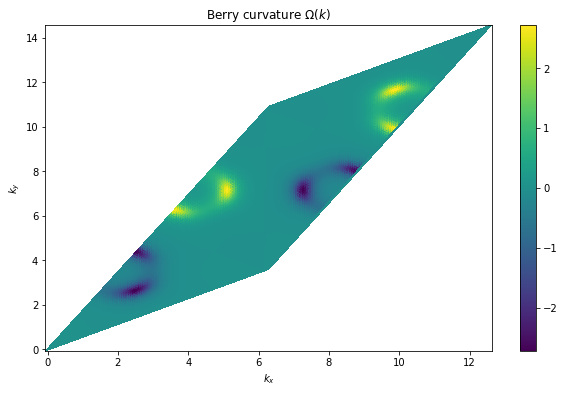

Plaquette area = 0.0046511325438335326
Chern number = -3.038132868985672e-16


In [17]:
wynik = 0.0
occ = [0, 1]

Bx = 0
By = 0
Bz = 0
Delta = -7.5
Onsite_A = -Delta/2
Onsite_B = Delta/2
faza = 0
faza_AB =  0
t_ab = 1
t_ba = 1
t_aa = 1
t_bb = 1

berry_flux = np.zeros((N2, N2))
berry_values = np.zeros((N2, N2))

dk1 = k1[1] - k1[0]
dk2 = k2[1] - k2[0]

a = dk1 * b1
b = dk2 * b3

plaquette_area = abs(a[0]*b[1] - a[1]*b[0])

hamiltonian = Hamiltonian(Onsite_A, Onsite_B, t_ab, t_ba, t_aa, t_bb, Hopping_tables, deltas_AB, deltas_BA, deltas_AA, deltas_BB, Bx, By, Bz) 

for i in range(N2 - 1):
    for j in range(N2 - 1):

        ene1, v1 = hamiltonian.problem_wlasny(grid_points[i][j][0], grid_points[i][j][1])
        ene2, v2 = hamiltonian.problem_wlasny(grid_points[i+1][j][0], grid_points[i+1][j][1])
        ene3, v3 = hamiltonian.problem_wlasny(grid_points[i+1][j+1][0], grid_points[i+1][j+1][1])
        ene4, v4 = hamiltonian.problem_wlasny(grid_points[i][j+1][0], grid_points[i][j+1][1])

        U1 = v1[:, occ]
        U2 = v2[:, occ]
        U3 = v3[:, occ]
        U4 = v4[:, occ]

        L12 = np.linalg.det(U1.conj().T @ U2)
        L23 = np.linalg.det(U2.conj().T @ U3)
        L34 = np.linalg.det(U3.conj().T @ U4)
        L41 = np.linalg.det(U4.conj().T @ U1)

        iloczyn = L12 * L23 * L34 * L41

        F = np.angle(iloczyn).item()

        berry_flux[i, j] = F
        berry_values[i, j] = F / plaquette_area

        wynik += F

chern = wynik / (2*np.pi)

plt.figure(figsize=(10, 6))
plt.pcolor(kx_values, ky_values, berry_values, shading="auto")
plt.title(r"Berry curvature $\Omega(k)$")
plt.colorbar()
plt.xlabel(r"$k_x$")
plt.ylabel(r"$k_y$")
plt.show()

print(f"Plaquette area = {plaquette_area}")
print(f"Chern number = {chern}")

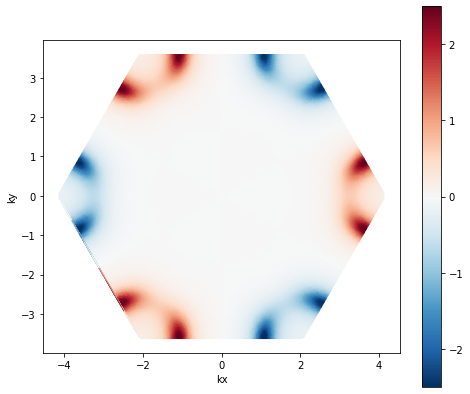

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

def fold_to_first_bz(k, b1, b2):
    best_k = None
    best_norm = np.inf
    for n1 in range(-2, 3):
        for n2 in range(-2, 3):
            candidate = k - n1*b1 - n2*b2
            norm = np.dot(candidate, candidate)
            if norm < best_norm:
                best_norm = norm
                best_k = candidate
    return best_k

folded_kx = []
folded_ky = []
folded_berry = []

for i in range(N2 - 1):
    for j in range(N2 - 1):
        center = 0.25 * (
            grid_points[i][j]
            + grid_points[i+1][j]
            + grid_points[i+1][j+1]
            + grid_points[i][j+1]
        )

        folded_center = fold_to_first_bz(center, b1, b2)

        folded_kx.append(folded_center[0])
        folded_ky.append(folded_center[1])
        folded_berry.append(berry_values[i][j])

folded_kx = np.array(folded_kx)
folded_ky = np.array(folded_ky)
folded_berry = np.array(folded_berry)

triang = mtri.Triangulation(folded_kx, folded_ky)

plt.figure(figsize=(8, 7))
plt.tripcolor(triang, folded_berry,
              shading='gouraud',
              cmap='RdBu_r',
              vmin=-2.5,
              vmax=2.5)
plt.colorbar()
plt.xlabel('kx')
plt.ylabel('ky')
# plt.title('Berry curvature in the first Brillouin zone')

plt.gca().set_aspect('equal')
# plt.savefig("Berry_35.png")
plt.show()

In [11]:
#Here we define functions that will be used to build MoTe2/WSe2 systems

v_ab = 1
v_ba = 1
sigma = 5
V0 = 50
x0 = 0
y0 = -10

def onsite_A(site, Bx, By, Bz, delta):
    x,y = site.pos
    return np.array([[-delta/2 + Bz + V0*np.exp((-(x-x0)**2 - (y-y0)**2)/(sigma)**2), Bx - 1j*By], [Bx + 1j*By, -delta/2 - Bz + V0*np.exp((-(x-x0)**2 - (y-y0)**2)/(sigma)**2)]])

def onsite_B(site, Bx, By, Bz, delta):
    x,y = site.pos
    return np.array([[+delta/2 + Bz + V0*np.exp((-(x-x0)**2 - (y-y0)**2)/(sigma)**2), Bx - 1j*By], [Bx + 1j*By, +delta/2 - Bz + V0*np.exp((-(x-x0)**2 - (y-y0)**2)/(sigma)**2)]])

def onsite_A_lead(site, Bx, By, Bz, delta):
    x,y = site.pos
    return np.array([[-delta/2 + Bz, Bx - 1j*By], [Bx + 1j*By, -delta/2 - Bz]])

def onsite_B_lead(site, Bx, By, Bz, delta):
    x,y = site.pos
    return np.array([[+delta/2 + Bz, Bx - 1j*By], [Bx + 1j*By, +delta/2 - Bz]])


def hopping_AA(site1, site2, faza, t_aa):
    t_AA_up = 1j*t_aa 
    t_AA_down = 1j*t_aa * (-1) 
    return np.array([[t_AA_up,0],[0,t_AA_down]])

def hopping_BB(site1, site2, faza, t_bb):
    t_BB_up = 1j*t_bb*(-1)
    t_BB_down = 1j*t_bb 
    return np.array([[t_BB_up,0],[0,t_BB_down]])
    

def potential_v0(x, y):
    return  

def hopping_AB(site1, site2, faza_AB, t_ab):
    Hopping_AB = np.exp(1j * v_ab * faza_AB)
    return np.array([[t_ab*Hopping_AB,0],[0,t_ab*Hopping_AB]])

def hopping_BA(site1, site2, faza_AB, t_ab):
    Hopping_BA = np.exp(1j * v_ba * faza_AB)
    return np.array([[t_ab*Hopping_BA,0],[0,t_ab*Hopping_BA]])

In [12]:
#Function that creates zigzag MoTe2/WSe2 system
def build_graphene_system_zigzag(Lmin=-15, Lmax=15, Wmin=-10, Wmax=10):

    sys_gr1 = kwant.Builder()
    # Lattice
    graphene_lat = kwant.lattice.general([[1, 0], [1/2, np.sqrt(3)/2]],
                                         [[0, 0], [0, 1/np.sqrt(3)]], norbs=2)
    lat_A, lat_B = graphene_lat.sublattices

    def ribbon(pos):
        x, y = pos
        return Lmin <= x <= Lmax and Wmin <= y <= Wmax


    sys_gr1 = kwant.Builder()
    sys_gr1[lat_A.shape(ribbon, (0, 0))] = onsite_A 
    sys_gr1[lat_B.shape(ribbon, (0, 0))] = onsite_B 

    sys_gr1[graphene_lat.neighbors()] = hopping_AB

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB

    def lead0_shape(pos):
        x, y = pos
        return Wmin <= y <= Wmax

    sym = kwant.TranslationalSymmetry([-1, 0])
    sym.add_site_family(graphene_lat.sublattices[0], other_vectors=[(-1, 2)])
    sym.add_site_family(graphene_lat.sublattices[1], other_vectors=[(-1, 2)])

    lead = kwant.Builder(sym)
    lead[lat_A.shape(lead0_shape, (0, 0))] = onsite_A_lead
    lead[lat_B.shape(lead0_shape, (0, 0))] = onsite_B_lead
    
    lead[graphene_lat.neighbors()] = hopping_AB

    lead[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA

    lead[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB

    sys_gr1.attach_lead(lead)
    sys_gr1.attach_lead(lead.reversed())

    return sys_gr1.finalized()


In [13]:
# In this cell, we plot the bandstructure of zigzag MoTe2/WSe2 system
def plot_wf(Bz=0, Bx=0, By=0, delta=30, t_aa=4):
#almost all parameters are defined here. They are passed to function "build_graphene_system" and then to onsite and hopping functions
    t_bb=t_aa
    t_ab = 4
    faza = 0
    faza_AB = 0
    sysf_zigzag = build_graphene_system_zigzag()

    kwant.plotter.bands(sysf_zigzag.leads[1], show=True, fig_size = (8,6), params=dict(Bx=Bx, By=By, Bz=Bz, delta=delta, t_ab = t_ab,
                                                                                        faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb));
    kwant.plotter.bands(sysf_zigzag.leads[1], show=False, fig_size = (8,6), params=dict(Bx=Bx, By=By, Bz=Bz, delta=delta, t_ab = t_ab, 
                                                                                         faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb));
    plt.ylim(-4,4)
    plt.grid()
    plt.show()
    
    wfs = kwant.wave_function(sysf_zigzag, energy=1, params=dict(Bx=Bx, By=By, Bz=Bz, delta=delta, t_ab = t_ab, 
                                                                                         faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb))
    scattering_wf = wfs(0)  # all scattering wave functions from lead 0
    
    psi = scattering_wf

    n_modes = psi.shape[0]
    n_sites = len(sysf_zigzag.sites)
    norbs = psi.shape[1] // n_sites
    
    params = dict(Bz=Bz,Bx=Bx,By=By,delta=delta,t_aa=t_aa,t_bb=t_bb,faza=faza,faza_AB=faza_AB,t_ab=t_ab)

    psi = scattering_wf

    n_modes = psi.shape[0]
    n_sites = len(sysf_zigzag.sites)
    norbs = psi.shape[1] // n_sites

    density = np.sum(abs(psi.reshape(n_modes, n_sites, norbs))**2, axis=(0, 2))

    kwant.plotter.map(sysf_zigzag, density)

    sigma_z = np.array([[1, 0],
                        [0, -1]])

    P_up = np.array([[1, 0],
                     [0, 0]])

    P_down = np.array([[0, 0],
                       [0, 1]])

    J_charge = kwant.operator.Current(sysf_zigzag)
    J_spin_z = kwant.operator.Current(sysf_zigzag, onsite=sigma_z)
    J_up = kwant.operator.Current(sysf_zigzag, onsite=P_up)
    J_down = kwant.operator.Current(sysf_zigzag, onsite=P_down)
    
    J_up = kwant.operator.Current(sysf_zigzag, onsite=P_up)
    J_down = kwant.operator.Current(sysf_zigzag, onsite=P_down)

#     for i, p in enumerate(scattering_wf):
#         print("mode =", i)

#         current_up_i = J_up(p, params=params)
#         current_down_i = J_down(p, params=params)

#         kwant.plotter.current(sysf_zigzag, current_up_i)
#         kwant.plotter.current(sysf_zigzag, current_down_i)

    current_charge = sum(J_charge(p, params=params) for p in psi)
    current_spin_z = sum(J_spin_z(p, params=params) for p in psi)
    current_up = sum(J_up(p, params=params) for p in psi)
    current_down = sum(J_down(p, params=params) for p in psi)

    kwant.plotter.current(sysf_zigzag, current_charge)
    kwant.plotter.current(sysf_zigzag, current_spin_z)
    kwant.plotter.current(sysf_zigzag, current_up)
    kwant.plotter.current(sysf_zigzag, current_down)
    
interact(plot_wf, Bz=(-10.0, 10.0), Bx=(-10.0, 10.0), By=(-10.0, 10.0), delta=(-60.0, 60.0), t_aa=(-10.0, 10.0));

interactive(children=(FloatSlider(value=0.0, description='Bz', max=10.0, min=-10.0), FloatSlider(value=0.0, de…